<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week13/Praktikum3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS13 - Artificial Neural Network (ANN) dan Evaluasi Classifier**<hr>
# **Praktikum 3**<hr>

## **Langkah 1 - Import Library**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

## **Langkah 2 - Load Dataset dan Preprocessing**
 Menggunakan California Housing sebagai pengganti Boston Housing yang sudah dihapus dari scikit-learn versi terbaru)

In [3]:
# Load dataset California Housing
data = fetch_california_housing()
X = data.data
y = data.target

# Normalisasi fitur
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# Split data (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(
    Xs, y, test_size=0.2, random_state=42
)

print("Shape X_train:", X_train.shape)
print("Shape y_train:", y_train.shape)

Shape X_train: (16512, 8)
Shape y_train: (16512,)


## **Langkah 3 - Membangun Model Regresi JST**

In [6]:
# Bangun model Sequential
model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])

# Tampilkan arsitektur
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

## **Langkah 4 - Kompilasi dan Latih Model**

In [7]:
# Kompilasi model
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

# Latih model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.7856 - mae: 0.6112 - val_loss: 0.4339 - val_mae: 0.4686
Epoch 2/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4045 - mae: 0.4482 - val_loss: 0.3929 - val_mae: 0.4581
Epoch 3/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3679 - mae: 0.4299 - val_loss: 0.3652 - val_mae: 0.4320
Epoch 4/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3505 - mae: 0.4170 - val_loss: 0.3660 - val_mae: 0.4418
Epoch 5/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3533 - mae: 0.4078 - val_loss: 0.3422 - val_mae: 0.4004
Epoch 6/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3221 - mae: 0.3971 - val_loss: 0.3203 - val_mae: 0.3918
Epoch 7/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3084 - mae: 0.3879 - val_loss: 0.3119 - val_mae: 0.3780
Epoch 8/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3052 - mae: 0.3843 - val_loss: 0.3277 - val_mae: 0.4124
Epoch 9/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - lo

## **Langkah 5 - Visualisasi Training dan Evaluasi**

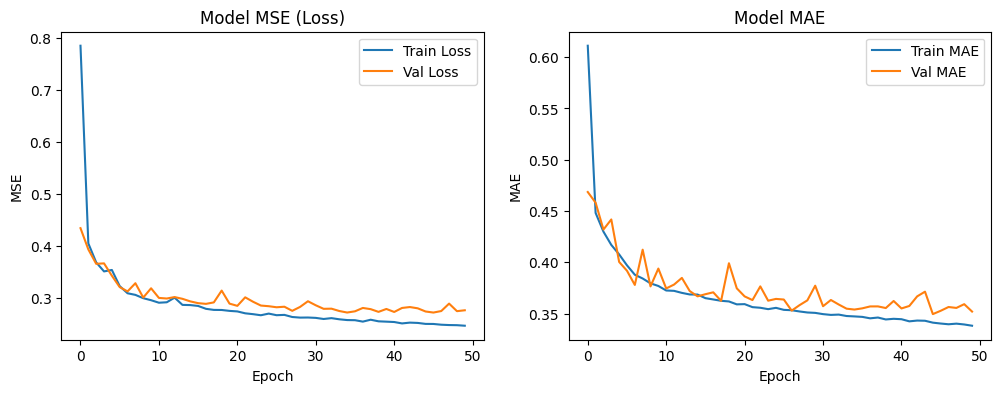

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

RMSE pada data validasi: 0.5250


In [8]:
# Plot Loss dan MAE
plt.figure(figsize=(12, 4))

# Plot MSE (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model MSE (Loss)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()

# Plot MAE
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Val MAE')
plt.title('Model MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.show()

# Evaluasi RMSE
pred = model.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, pred))
print(f"\nRMSE pada data validasi: {rmse:.4f}")

---
# **TUGAS 4 - Pengaruh Learning Rate terhadap Loss**


In [11]:
def train_with_lr(lr):
    m = Sequential([
        tf.keras.Input(shape=(X_train.shape[1],)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    m.compile(optimizer=Adam(learning_rate=lr), loss='mse')

    h = m.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)
    return h.history['loss'][-1]

# Uji beberapa learning rate
lrs = [0.0001, 0.001, 0.01, 0.1]

print("Eksperimen Learning Rate (50 Epoch):")
for lr in lrs:
    final_loss = train_with_lr(lr)
    print(f"LR {lr:>6} -> Final Loss (MSE): {final_loss:.4f}")

Eksperimen Learning Rate (50 Epoch):
LR 0.0001 -> Final Loss (MSE): 0.3145
LR  0.001 -> Final Loss (MSE): 0.2434
LR   0.01 -> Final Loss (MSE): 0.2568
LR    0.1 -> Final Loss (MSE): 0.4249


**Analisis Tugas 4:**

| Learning Rate | Final Loss (MSE) | Catatan |
|---------------|------------------|---------|
| 0.0001        | 0.3145           | Konvergensi lambat karena *step* pembaruan bobot terlalu kecil. |
| 0.001         | 0.2434           | Nilai paling optimal, mencapai loss terendah dengan stabil. |
| 0.01          | 0.2568           | Cepat di awal, tapi *loss* akhirnya sedikit lebih tinggi. |
| 0.1           | 0.4249           | Terlalu besar, model *overshoot* (melewati titik minimum). |

**Kesimpulan:**
Berdasarkan eksperimen, *learning rate* sangat memengaruhi performa model regresi. Nilai **0.001** menjadi *learning rate* paling optimal karena menghasilkan *Final Loss* terendah (0.2434), yang menandakan model berhasil mencapai titik konvergensi dengan baik.

Jika *learning rate* terlalu kecil (0.0001), proses pembelajaran menjadi sangat lambat sehingga belum mencapai *loss* minimum di epoch ke-50. Sebaliknya, jika terlalu besar (0.1), model akan gagal konvergen karena pergerakan bobotnya terlalu jauh dan melompati titik minimum (overshoot), sehingga *loss* akhirnya justru membesar (0.4249).